# 02 · City B Viana do Castelo: stream profile and prequential experiment

**PA04 · Textile storage facility (humid vs. dry regimes) · T4 Humid vs Dry Regime**
**Author:** Victoriya Yurevna (20230796), Student B · **Primary city:** Viana do Castelo

* **Business context:** textile storage facility (humid vs. dry regimes)
* **Locations:** Guimarães vs Viana do Castelo
* **Question:** How do humid and dry regimes differ between candidate warehouse locations?

Individual notebook. Prerequisite: `00_shared_protocol` has been run (shared protocol checks and records).
The setup cell loads the shared protocol; the guide below shows how to use the modules in `src/`.

<div class="alert alert-block alert-warning" style="background-color:#ffe94d; border:4px solid #ff8c00; border-radius:6px; padding:14px 18px; color:#000000;">

> ⚠️ **TEMPORARY NOTE: DELETE THIS CELL BEFORE SUBMISSION.**
> Working guidance for the two of us while we experiment. It is not part of the deliverable.

## Experimenting without breaking the shared protocol

Both city notebooks must produce **official results under the identical protocol**, so that `03_shared_comparison` compares like with like (Ch. 3.1). Experiments are welcome on top of that, as long as they never change or replace the official run.

### Fixed by the shared protocol: never change these here
* Data: period, cities, variables, source (`config.yaml → data`, `cities`).
* Warm-up (first 12 months) and τ_H (Q0.50 of the pooled warm-up = 82 %, frozen).
* Target T4: y = 1 if RH_t ≥ τ_H.
* Strict chronological order and PREDICT → EVALUATE → LEARN (`evaluate.run_prequential`).
* The official run: the 5 mandatory models, Representations A and B, and the settings in `config.yaml`.
* Leakage rules: RH at t is never a predictor, and nothing is fitted on evaluation data.

### Open for experiments (tested with the current modules)

| Experiment | How |
|---|---|
| Other window sizes, rolling statistics of other variables | `my_cfg["features"]["windows"] = [3, 12, 48]`; `my_cfg["features"]["rolling_variables"] += ["temperature_2m"]`, then `make_streams(prepared, my_cfg)[CITY_KEY]`. `from features import check_no_leakage; check_no_leakage(prepared["raw"][CITY_KEY], TAU_H, my_cfg)` also covers these features. |
| Your own features (e.g. hour of day, dew point at t−1, rain over the last 24 h) | Add them to each event after `make_streams`: `e["x"]["hour_sin"] = ...`. Use only values up to t−1, or calendar values (known in advance). These are not checked by `check_no_leakage` and not scaled, so if you scale them, fit the scaling on the warm-up only. |
| Hyper-parameters | `my_cfg["models"]["hoeffding"]["grace_period"] = 200`, `my_cfg["models"]["ensemble_size"]`, `arf_lambda`, `logistic_lr`, … then `evaluate_models(streams, make_models, my_cfg, CITY_KEY)`. |
| Extra models next to the mandatory five | Any River classifier: `from river import neighbors, tree`, then `extra = lambda c: {"Hoeffding Adaptive Tree": tree.HoeffdingAdaptiveTreeClassifier(seed=c["protocol"]["seed"]), "kNN": neighbors.KNNClassifier()}`, then `evaluate_models(streams, extra, cfg, CITY_KEY)`. |
| Another "recent performance" window | `my_cfg["protocol"]["evaluation_window"] = 168` |
| Original descriptive analyses (Ch. 3.2) | Fully open, on `profile["df"]`. |
| Business-risk views (descriptive only) | e.g. `profiling.episodes(df.assign(y=(df["relative_humidity_2m"] >= 90).astype(float)))`. Never redefine the T4 target. |

**Not possible yet: scores per season or per month, or errors during long humid episodes.** `run_prequential` does not keep each individual prediction. Do not rewrite the evaluation loop in this notebook. Instead, we can add an option to `evaluate.py` that is off by default (so the official run is unchanged), and only after we agree on it together.

### Rules that preserve the shared structure
1. **Always experiment on a copy:** `import copy; my_cfg = copy.deepcopy(cfg)`. Never edit `cfg` in place.
2. **Never call `save_results` or `profiling.save_profile` with a modified configuration.** These write the official files that notebook 03 reads.
3. **Name experiment figures `<city_key>_exp_<name>`**, so they can never overwrite an official figure.
4. **Never edit `config.yaml` or `src/` alone.** Both change the other city's results too. Propose the change, agree, then both re-run.
5. **Keep experiments in their own clearly titled section**, separate from the official results, and report them as additional analysis.
6. **Promoting an experiment to the official run is a joint decision:** change `config.yaml` together, then re-run `00`, `01`, `02` and `03`.

</div>

## 1. Setup

**Requirement (Ch. 3.1, 12.2–12.4):** use the shared protocol. τ_H, the warm-up and the target come from `data.prepare_frames`, exactly as in `00_shared_protocol` and `01_cityA_guimaraes`; nothing is set by hand here.

In [1]:
CITY_KEY = "viana_do_castelo"              # the only line that differs between the two city notebooks

import sys
from pathlib import Path

# Make src/ importable whatever folder Jupyter was started from
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.yaml").exists())
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
import matplotlib.pyplot as plt

import plots
import profiling
from data import prepare_frames
from evaluate import evaluate_models, save_results
from features import make_streams
from models import make_models
from utils import load_config, output_dir

plots.set_style()
cfg = load_config()
prepared = prepare_frames(cfg)                 # shared protocol: same tau_H, warm-up and target as notebook 00
CITY = next(c for c in cfg["cities"] if c["key"] == CITY_KEY)
TAU_H = prepared["tau"]
df = prepared["frames"][CITY_KEY]              # this city's stream: timestamps, 4 variables, quality_flag, phase, y
print(f"{CITY['role']}: {CITY['name']}  |  {len(df)} hours  |  tau_H = {TAU_H:.2f} %")

City B: Viana do Castelo  |  26304 hours  |  tau_H = 82.00 %


In [2]:
import copy
import numpy as np
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap

from evaluate import run_prequential
from features import check_no_leakage
from plots import BLUE, ORANGE, AQUA, INK_2, GREY, MODEL_COLORS, HUMID, DRY

pd.set_option("display.float_format", lambda v: f"{v:.4f}")
profile = profiling.profile_city(df, TAU_H, cfg)      # every descriptive table of this city, one call
pdf = profile["df"]                                   # stream + local_time, hour, month, year, season
EVAL = pdf["phase"] == "evaluation"

### 1.1 Stream card

**Requirement (Ch. 15, 15.2):** state the grid point and period actually used. Open-Meteo snaps the requested coordinates to its model grid.

In [3]:
payload = prepared["payloads"][CITY_KEY]
card = pd.Series({
    "city / role": f"{CITY['name']} / {CITY['role']}",
    "requested point (lat, lon)": f"{CITY['latitude']:.3f}, {CITY['longitude']:.3f}",
    "grid point used (lat, lon)": f"{payload['latitude']:.3f}, {payload['longitude']:.3f}",
    "grid elevation (m)": payload["elevation"],
    "period": f"{pdf['timestamp'].min():%Y-%m-%d} to {pdf['timestamp'].max():%Y-%m-%d}",
    "hours": len(pdf),
    "warm-up (learn only)": f"{(~EVAL).sum()} h, until {prepared['warmup_end']:%Y-%m-%d %H:%M}",
    "evaluation (prequential)": f"{EVAL.sum()} h, from {prepared['evaluation_start']:%Y-%m-%d}",
    "tau_H (pooled warm-up, frozen)": f"{TAU_H:.1f} %",
}, name="value")
card.to_frame()

,value
city / role,Viana do Castelo / City B
"requested point (lat, lon)","41.695, -8.829"
"grid point used (lat, lon)","41.722, -8.857"
grid elevation (m),15.0000
period,2023-01-01 to 2025-12-31
hours,26304
warm-up (learn only),"8760 h, until 2023-12-31 23:00"
evaluation (prequential),"17544 h, from 2024-01-01"
"tau_H (pooled warm-up, frozen)",82.0 %


* The Viana do Castelo grid cell lies at about **15 m** above sea level and is shifted ~3 km north-west of the requested point, i.e. it is a **coastal** cell (City A's cell is at 170 m, inland). Coastal exposure is the main physical difference between the two candidate sites.

> 📝 **For the report:** is this grid cell representative of a warehouse in Viana do Castelo (coast vs. town, elevation)?

## 2. Data quality, missing and invalid observations

**Requirement (Ch. 9 item 1, Ch. 18):** inspect missing and invalid values. **Extreme ≠ erroneous** (Ch. 9): saturated air (RH = 100 %) or a storm is real weather and may be exactly what a textile store must anticipate. Nothing is deleted.

In [4]:
display(profile["quality"])
profile["special"].to_frame("value")

,missing,flagged invalid,longest constant run (h),distinct values,unit
Temperature,0,0,8,274,°C
Relative humidity,0,0,24,72,%
Precipitation,0,0,523,104,mm
Wind speed,0,0,5,511,km/h


,value
"RH = 100 % (saturation), hours",462.0000
"RH = 100 %, share",0.0176
"wind = 0 km/h (calm), hours",3.0000
"precipitation > 0 mm, hours",6101.0000
"precipitation > 0 mm, share",0.2319


* **No missing and no invalid values** in any of the four variables (26 304 hours). No observation was removed or corrected.
* The longest constant run of RH is 24 h (RH = 100 % from 1 Oct 2024 17:00 to 2 Oct 16:00). It is saturation, not a frozen sensor: temperature (12 different values) and wind (23 values) keep changing in the same hours. Precipitation is constant (0 mm) for up to 523 h, which is a dry spell, not an error.
* **RH = 100 % in 462 hours (1.8 %)**: saturation, kept as valid observations. All of them are humid hours (y = 1).
* Only 3 calm hours (wind = 0 km/h): the coastal cell is almost always ventilated.

> 📝 **For the report:** summarise the quality result for Viana do Castelo in 1–2 sentences and justify why nothing was removed.

## 3. Descriptive statistics of the main weather variables

**Requirement (Ch. 9 item 2).** Whole period, warm-up vs. evaluation (is the evaluation period comparable with the year τ_H was estimated on?), and seasons (DJF = winter, MAM = spring, JJA = summer, SON = autumn).

In [5]:
display(profile["describe"])
display(profile["by_phase"])
profile["by_season"]

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,skew
Temperature (°C),26304.0000,15.3981,4.1052,1.6000,5.7000,8.5000,12.7000,15.4000,18.2000,21.9000,25.3000,30.9000,-0.0276
Relative humidity (%),26304.0000,80.4358,12.1777,27.0000,47.0000,58.0000,73.0000,82.0000,90.0000,97.0000,100.0000,100.0000,-0.6480
Precipitation (mm),26304.0000,0.2021,0.7592,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.2000,3.9000,16.1000,7.0966
Wind speed (km/h),26304.0000,15.3934,9.0656,0.0000,1.4000,3.3000,8.3000,14.1000,21.0000,31.9000,40.8000,57.5000,0.7431


phase                     warm-up  evaluation
Temperature       mean    15.6038     15.2953
                  std      4.4065      3.9422
                  median  16.0000     15.2000
Relative humidity mean    79.9022     80.7023
                  std     12.4253     12.0437
                  median  82.0000     82.0000
Precipitation     mean     0.1980      0.2042
                  std      0.7860      0.7455
                  median   0.0000      0.0000
Wind speed        mean    14.8306     15.6745
                  std      8.7375      9.2125
                  median  13.6000     14.4000

,Temperature,Relative humidity,Precipitation,Wind speed,humid share (y=1)
season,,,,,
DJF,11.4968,79.1579,0.2724,15.1233,0.4783
MAM,14.3366,78.2303,0.1896,15.5438,0.4452
JJA,19.1030,82.2671,0.0464,15.9144,0.5560
SON,16.5972,82.0810,0.3024,14.9831,0.5783


* Mean RH is **80.4 %** with a median of **82 %**, exactly at τ_H: half of all hours sit on either side of the threshold, so the target is balanced but many hours are close to the boundary (see Section 9).
* Temperature is mild and narrow (P5–P95: 8.5–21.9 °C, std 4.1 °C): a maritime climate with small daily and annual amplitude.
* Warm-up (2023) and evaluation (2024–2025) are very similar (RH mean 79.9 % vs. 80.7 %, same median 82 %), so the frozen threshold remains meaningful during evaluation.
* By season, **summer (JJA) and autumn (SON) are the most humid** (mean RH ≈ 82 %), spring the least (78 %). Summer is also the driest in rain (0.05 mm/h): summer humidity here is not caused by rain.
* Wind is strong for a city (mean 15.4 km/h, P95 32 km/h), consistent with an exposed coastal site.

> 📝 **For the report:** which variables and seasons matter for a textile store, and what does the summer humidity without rain suggest (sea air, fog)?

## 4. Temporal evolution

**Requirement (Ch. 9 item 3).** Figure 1: daily means (daily total for rain) over the three years, warm-up marked. Figure 2: hourly RH by calendar month against τ_H.

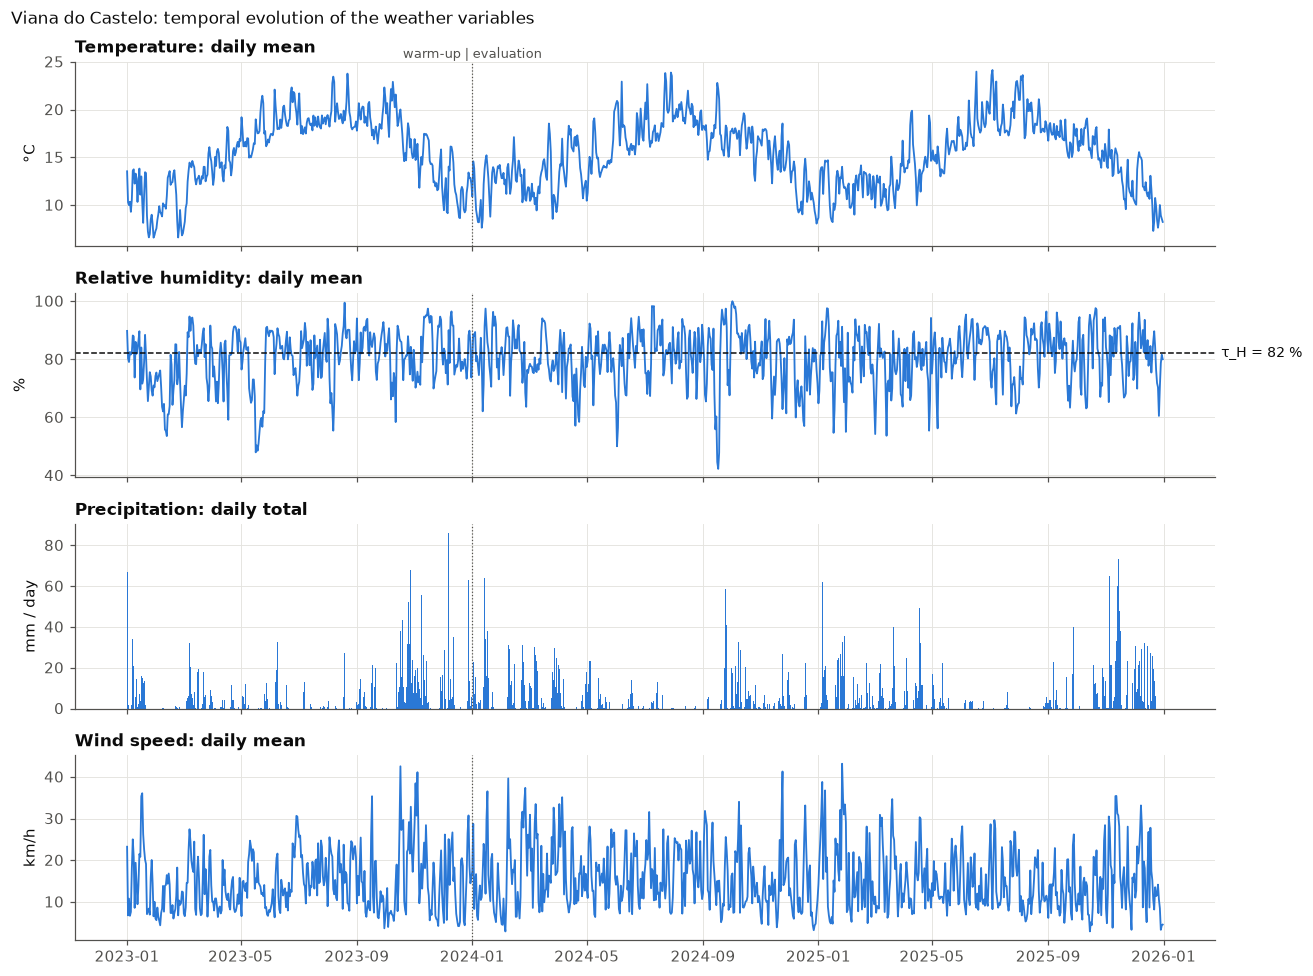

In [6]:
fig = plots.daily_evolution(profile, prepared, cfg, CITY["name"])
plots.save(fig, cfg, f"{CITY_KEY}_01_daily_evolution")
plt.show()

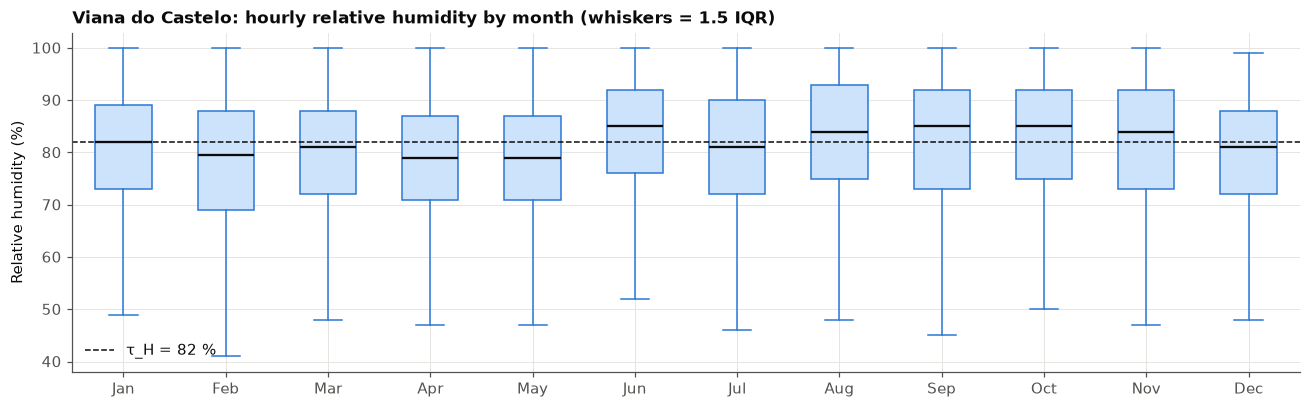

In [7]:
fig = plots.rh_by_month(profile, prepared, cfg, CITY["name"])
plots.save(fig, cfg, f"{CITY_KEY}_02_rh_by_month")
plt.show()

* Temperature follows a clear annual cycle; RH has only a **weak annual cycle**: its monthly medians stay between 79 % and 85 %, i.e. close to τ_H all year. They are above τ_H in June and from August to November (84–85 %) and below it in February, April and May (≈ 79 %).
* The three years look alike, and the warm-up/evaluation boundary does not mark a change of regime.
* The spread inside each month is wide (dry spells below 60 % next to saturated hours), so the regime is decided hour by hour rather than by the season.

> 📝 **For the report:** describe the main temporal patterns you see and why they matter for environmental control in the store.

## 5. Target frequency and class distribution

**Requirement (Ch. 9 item 4, Ch. 11.1):** inspect the class balance before modelling; it decides which metrics can be trusted. T4: y = 1 (humid) if RH_t ≥ τ_H = 82 %.

In [8]:
display(profile["class_by_phase"])
display(profile["class_by_year"])
profile["class_by_season"]

,hours,humid_hours,humid_share,dry_share
phase,,,,
warm-up,8760,4383.0000,0.5003,0.4997
evaluation,17544,9150.0000,0.5215,0.4785


,hours,humid_hours,humid_share,dry_share
year,,,,
2023,8760,4383.0000,0.5003,0.4997
2024,8784,4533.0000,0.5161,0.4839
2025,8760,4617.0000,0.5271,0.4729


,hours,humid_hours,humid_share,dry_share
season,,,,
DJF,6504,3111.0000,0.4783,0.5217
MAM,6621,2948.0000,0.4452,0.5548
JJA,6624,3683.0000,0.5560,0.4440
SON,6555,3791.0000,0.5783,0.4217


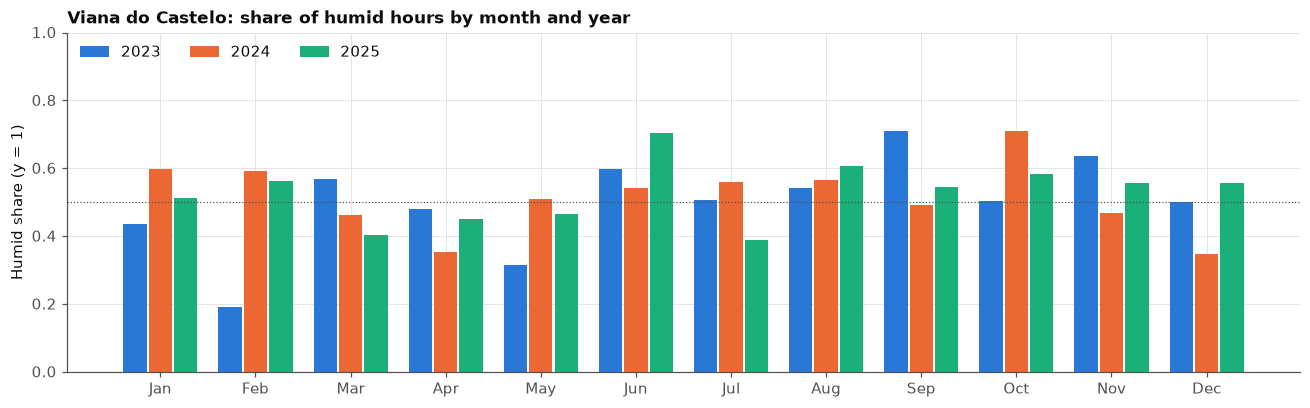

In [9]:
fig = plots.humid_share_month_year(profile, CITY["name"])
plots.save(fig, cfg, f"{CITY_KEY}_03_humid_share_month_year")
plt.show()

* The classes are **balanced**: 50.0 % humid in the warm-up and 52.2 % in the evaluation period, rising slightly each year (2023: 50.0 %, 2024: 51.6 %, 2025: 52.7 %). The majority-class rule would score only 52.2 % accuracy, so Accuracy is informative here, but Macro-F1 and Recall on the humid class are still reported (Ch. 11.1).
* **Seasonality of the event:** humid hours are most frequent in **autumn (57.8 %) and summer (55.6 %)** and least frequent in spring (44.5 %).
* The pattern repeats each year (Figure 3), so it is a property of the site rather than of a single year.

> 📝 **For the report:** what does this class balance mean for the choice of metrics, and in which season is the store most exposed?

## 6. Rolling and window behaviour

**Requirement (Ch. 9 item 5).** The same windows the models use in Representation B (6 h and 24 h, ending at t−1) plus a 7-day humid share. Figure 4: three years; Figure 5: two weeks in detail.

In [10]:
profile["rolling_by_season"]

,rh_std_6h,rh_std_24h,humid_share_7d
season,,,
DJF,3.0166,6.6255,0.5179
MAM,3.5449,7.4128,0.4405
JJA,3.1331,7.5266,0.5774
SON,2.8107,6.2819,0.5774


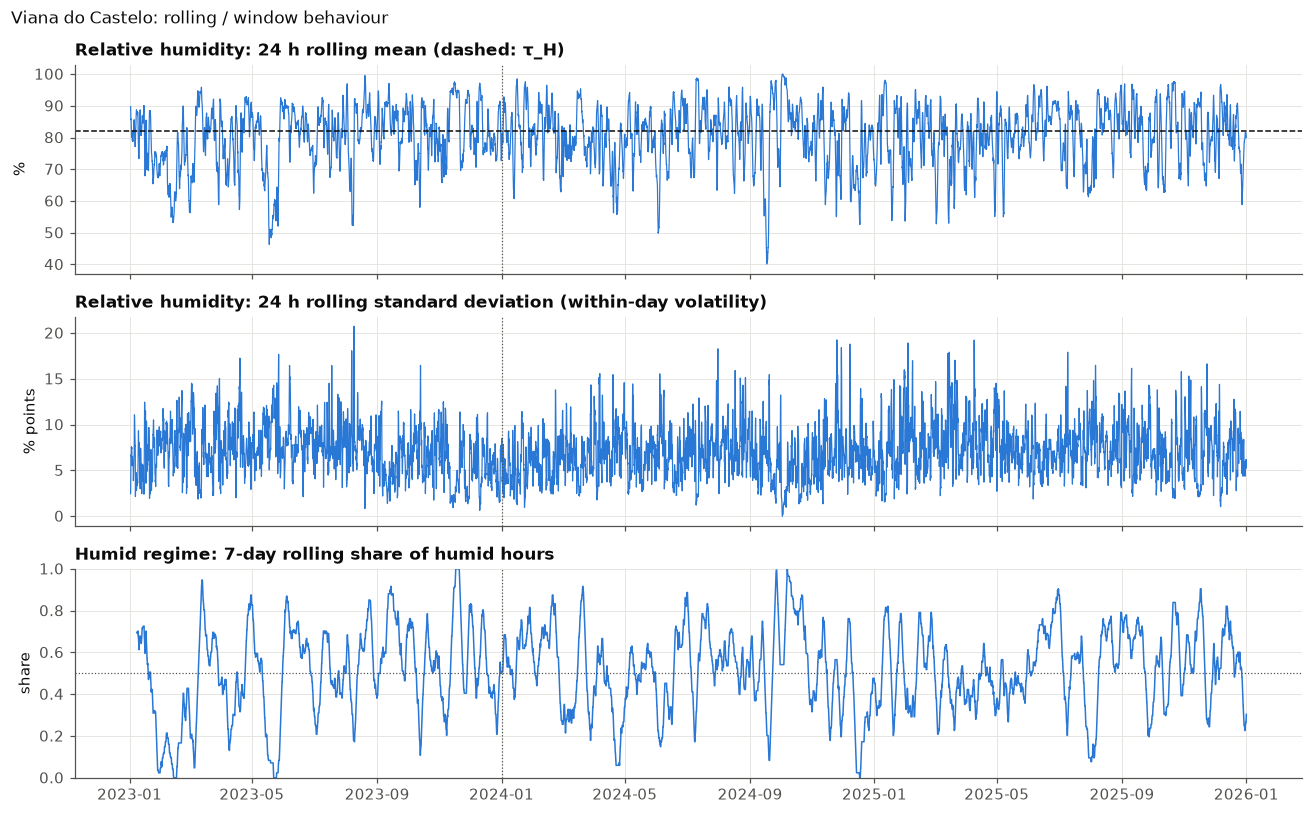

In [11]:
fig = plots.rolling_overview(profile, prepared, CITY["name"])
plots.save(fig, cfg, f"{CITY_KEY}_04_rolling_overview")
plt.show()

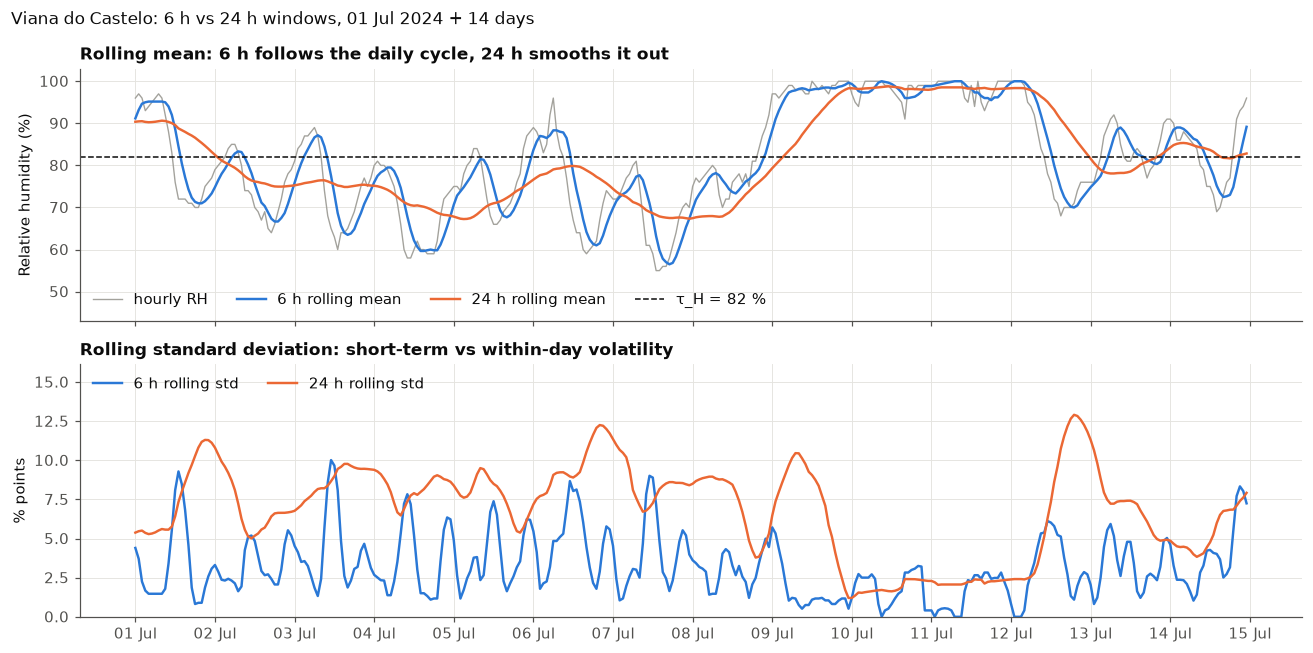

In [12]:
ZOOM_START = "2024-07-01"     # same excerpt in both city notebooks, so Figure 5 is comparable
fig = plots.rolling_zoom(profile, prepared, cfg, CITY["name"], start=ZOOM_START, days=14)
plots.save(fig, cfg, f"{CITY_KEY}_05_rolling_zoom")
plt.show()

* Short-term variability is small: the median 6 h std of RH is about 3 percentage points and the 24 h std about 6–7.5 points, lowest in autumn and winter.
* The 7-day humid share moves between dry and humid weeks, peaking in summer and autumn (≈ 58 %) and dipping in spring (44 %).
* In the July 2024 excerpt, the first week shows the daily cycle (RH swinging between ≈ 57 % and 95 %): the 6 h mean follows it, the 24 h mean smooths it away. From 9 to 12 July the air stays saturated (≈ 95–100 %) for more than three days in midsummer; there the 6 h std drops to ≈ 0. The two windows therefore carry different information: recent change vs. the background level.

> 📝 **For the report:** what do the 6 h and 24 h windows "see" differently, and why could that help the models (Representation B)?

## 7. Unusual and extreme observations

**Requirement (Ch. 9 item 6).** Tails (below P1 / above P99), the most extreme hours and days. They are inspected, never removed.

In [13]:
display(profile["extremes"])
display(profile["top_extremes"])
profiling.extreme_days(profile["daily"])

,P1,P99,hours < P1,hours > P99,hours outside 1.5 IQR,min,max
Temperature,5.7000,25.3000,260.0000,248.0000,204.0000,1.6000,30.9000
Relative humidity,47.0000,100.0000,242.0000,0.0000,293.0000,27.0000,100.0000
Precipitation,0.0000,3.9000,0.0000,263.0000,6101.0000,0.0000,16.1000
Wind speed,1.4000,40.8000,263.0000,263.0000,316.0000,0.0000,57.5000


,variable,kind,timestamp,value,RH at that hour,y
0,Temperature,highest,2024-07-29 18:00:00,30.9000,60,0.0000
1,Temperature,highest,2024-07-29 19:00:00,30.9000,56,0.0000
2,Temperature,highest,2024-07-29 15:00:00,30.6000,55,0.0000
3,Temperature,highest,2024-07-29 17:00:00,30.2000,67,0.0000
4,Temperature,highest,2025-08-05 16:00:00,29.8000,50,0.0000
5,Temperature,lowest,2023-02-28 07:00:00,1.6000,74,0.0000
6,Temperature,lowest,2023-02-28 08:00:00,1.7000,70,0.0000
7,Temperature,lowest,2023-01-24 09:00:00,1.9000,78,0.0000
8,Temperature,lowest,2023-01-24 08:00:00,2.1000,81,0.0000
9,Temperature,lowest,2023-03-02 07:00:00,2.1000,80,0.0000


value
                            timestamp          
wettest days (mm)           2023-12-07  86.1000
                            2025-11-14  73.5000
                            2023-10-28  67.7000
                            2023-01-01  67.1000
                            2025-11-05  64.9000
driest days (mean RH %)     2024-09-17  42.2000
                            2024-09-16  44.6000
                            2024-09-18  47.8000
                            2023-05-17  48.0000
                            2023-05-19  48.5000
most humid days (mean RH %) 2024-10-02 100.0000
                            2023-08-19  99.5000
                            2024-10-03  99.2000
                            2024-10-01  98.6000
                            2024-07-09  98.3000

* **No physically impossible values.** The extremes are real weather events: a heat episode on 29 July 2024 (30.9 °C, RH 55–67 %, dry), cold mornings in early 2023 (1.6 °C), storms with 55–57 km/h winds (March, April and October 2024), and wet days up to 86 mm (7 Dec 2023).
* Heavy rain and storm hours are all **humid** (RH 87–98 %), while the hottest hours are dry: in this stream extremes of rain and wind push towards the humid regime.
* The driest days (16–18 Sep 2024, mean RH 42–48 %) and the most humid days (1–3 Oct 2024, mean RH ≈ 99–100 %) are only two weeks apart: sharp regime swings occur.

> 📝 **For the report:** are these extremes relevant for the store (e.g. storm days, saturated days), and why are they kept?

## 8. Original analyses (Ch. 3.2)

Three analyses that go beyond the starter-code figures and answer the business question directly: **how long** humid regimes last, **when** they occur during the day, and **how many hours** of the year fall into long, risky humid spells.

### 8.1 Persistence of the regimes: episode durations

An *episode* is a run of consecutive hours in the same regime. For textiles, a long humid episode is what matters (moisture uptake, mould), not a single humid hour.

In [14]:
display(profile["persistence"])
profile["humid_episodes_by_season"]

,dry,humid
episodes,1114.0000,1115.0000
mean (h),11.4641,12.1372
median (h),6.5000,7.0000
P90 (h),24.0000,26.0000
max (h),237.0000,252.0000
episodes ≥ 24 h,114.0000,128.0000
episodes ≥ 72 h,14.0000,15.0000
share of regime hours in episodes ≥ 24 h,0.4654,0.4518


,episodes,mean_h,median_h,max_h
season,,,,
DJF,281,11.0747,6.0000,104
MAM,317,9.4196,5.0000,119
JJA,263,14.0837,13.0000,87
SON,254,14.6890,7.0000,252


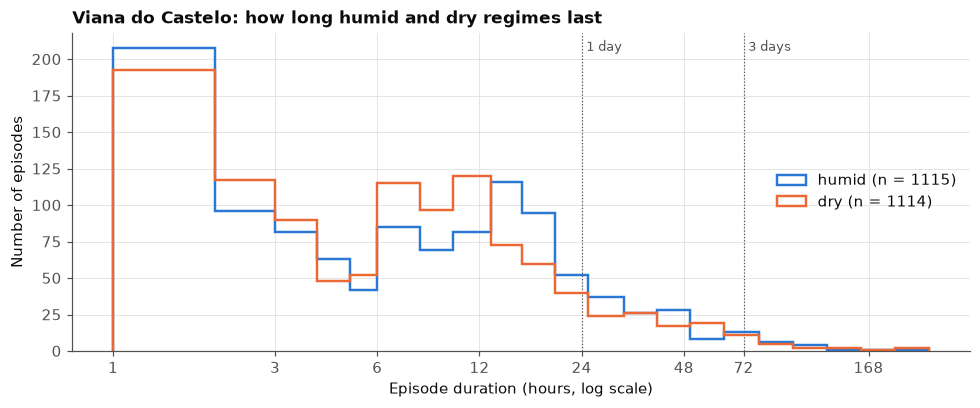

In [15]:
fig = plots.episode_durations(profile, CITY["name"])
plots.save(fig, cfg, f"{CITY_KEY}_06_episode_durations")
plt.show()

* About 1 115 humid episodes in three years, **mean 12.1 h, median 7 h**, but with a long tail: **128 humid episodes last ≥ 24 h, 15 last ≥ 72 h, and the longest lasts 252 h (10.5 days)**.
* **45 % of all humid hours belong to episodes of 24 h or more.** Humid air arrives in long spells, not only in short night-time peaks.
* Summer humid episodes have the longest median (13 h); the longest spells occur in autumn (max 252 h) and spring (119 h).

> 📝 **For the report:** what do long humid episodes mean for a textile store (dehumidification, ventilation, mould risk)?

### 8.2 When is the air humid? Month × local hour

Share of humid hours for each calendar month and local hour (true local clock, with summer time).

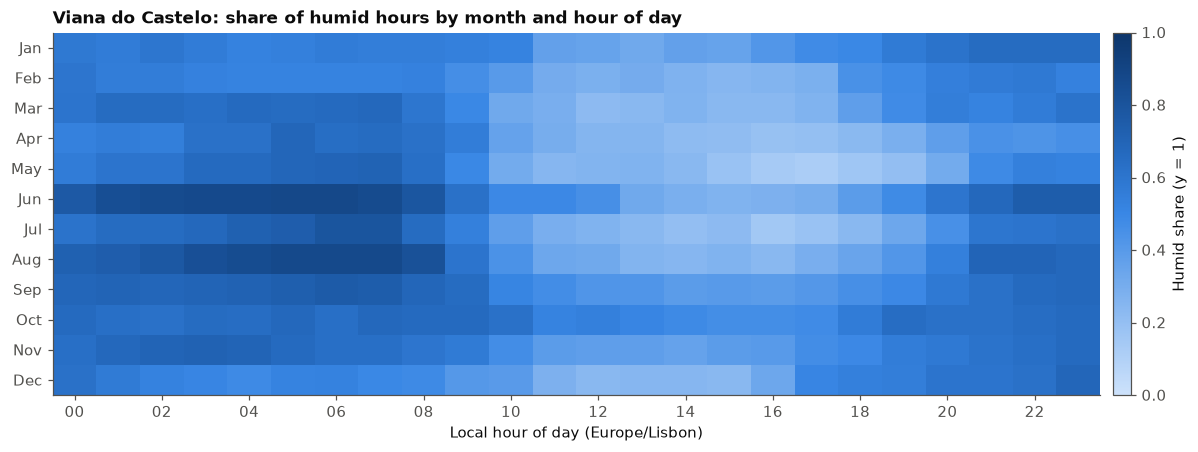

,most humid hour,max share,least humid hour,min share,amplitude (max - min)
season,,,,,
DJF,23,0.6273,15,0.2804,0.3469
MAM,7,0.6812,16,0.1884,0.4928
JJA,6,0.8478,16,0.2210,0.6268
SON,5,0.6923,14,0.4103,0.2821


In [16]:
fig = plots.hour_month_heatmap(profile, CITY["name"])
plots.save(fig, cfg, f"{CITY_KEY}_07_hour_month_heatmap")
plt.show()
profile["daily_cycle"]

* A strong **daily cycle**: humid nights and mornings (most humid hour 05–07 h, except winter at 23 h) and drier afternoons (least humid hour 14–16 h).
* The cycle is strongest in **summer**: at 06 h 85 % of June–August mornings are humid, at 16 h only 22 % (amplitude 0.63).
* In **autumn (Sep–Nov) the afternoons stay humid too** (≈ 35–55 %): the dry afternoon window that exists in spring and summer shrinks.

> 📝 **For the report:** is there a daily "dry window" for ventilating the store, and in which months does it disappear?

### 8.3 Hours in long humid spells, month by month

Each hour is labelled with the length of the episode it belongs to. **Risk hours** = humid hours inside an episode of at least 24 h. This turns 8.1 into a calendar: when, and how many hours, the store would face a sustained humid spell.

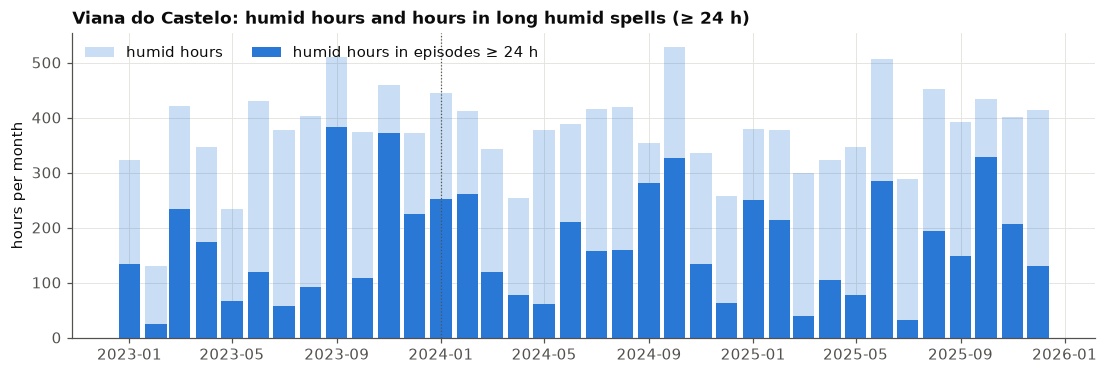

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
humid,383.0000,307.0000,355.0000,308.0000,320.0000,442.0000,360.0000,425.0000,419.0000,445.0000,399.0000,348.0000
risk,213.0000,167.0000,131.0000,119.0000,68.0000,205.0000,83.0000,149.0000,271.0000,255.0000,238.0000,140.0000


In [17]:
LONG_H = 24
run_id = (pdf["y"] != pdf["y"].shift()).cumsum()
run_len = pdf.groupby(run_id)["y"].transform("size")
risk = (pdf["y"] == 1) & (run_len >= LONG_H)

monthly = (pdf.assign(risk=risk, humid=pdf["y"] == 1)
              .groupby(pdf["timestamp"].dt.to_period("M"))[["humid", "risk"]].sum())
monthly["risk share of humid hours"] = monthly["risk"] / monthly["humid"]

fig, ax = plt.subplots(figsize=(12, 3.6))
x = monthly.index.to_timestamp()
ax.bar(x, monthly["humid"], width=25, color=HUMID, alpha=0.25, label="humid hours")
ax.bar(x, monthly["risk"], width=25, color=HUMID, label=f"humid hours in episodes ≥ {LONG_H} h")
ax.axvline(prepared["evaluation_start"], color=INK_2, linewidth=0.8, linestyle=":")
ax.set_ylabel("hours per month")
ax.set_title(f"{CITY['name']}: humid hours and hours in long humid spells (≥ {LONG_H} h)", loc="left")
ax.legend(loc="upper left", ncol=2)
plots.save(fig, cfg, f"{CITY_KEY}_08_long_humid_spells")
plt.show()

by_month = monthly.groupby(monthly.index.month)[["humid", "risk"]].mean().round(0)
by_month.index = plots.MONTHS
by_month.T

* Long humid spells are concentrated in **autumn and winter**: on average September (271 risk hours per month), October (255), November (238) and January (213) have the most hours inside spells of ≥ 24 h, i.e. 55–65 % of their humid hours.
* **June is the summer exception** (205 risk hours, 46 % of its humid hours), while in **May and July most humid hours come in short, mostly night-time episodes** (only 21–23 % in long spells).
* Monthly totals vary between years (Figure 8), so the risk comes in specific weeks rather than evenly through a season.

> 📝 **For the report:** in which months should the store expect sustained humid spells, and how would you use this for planning (dehumidifier capacity, stock rotation)?

### 8.4 Save the profile tables

Used by `03_shared_comparison` (key numbers, episodes) and by the report.

In [18]:
profiling.save_profile(profile, CITY_KEY, output_dir(cfg, "profiles_dir"))
profile["key_numbers"].to_frame()

,value
tau_H,82.0000
humid_share_all,0.5145
humid_share_warmup,0.5003
humid_share_evaluation,0.5215
humid_share_DJF,0.4783
humid_share_MAM,0.4452
humid_share_JJA,0.5560
humid_share_SON,0.5783
rh_mean,80.4358
rh_std,12.1777


## 9. Business interpretation of the Viana do Castelo stream

**Requirement (Ch. 9 item 7, Ch. 13.1).** Descriptive evidence only; the comparison with Guimarães is in `03_shared_comparison`.

* Humid hours make up about half of the year (51 %) at τ_H = 82 %, with the highest exposure in **summer and autumn**.
* The regime is **persistent**: long humid spells (≥ 24 h) hold 45 % of all humid hours and can last up to ten days.
* There is a usable **daily dry window** in the afternoon in spring and summer; it shrinks in autumn.

> 📝 **For the report:** in your own words, what does this stream mean for a textile storage facility in Viana do Castelo?

## 10. Prequential experiment: official run

**Requirements (Ch. 7, 8, 10–12):** two representations, five mandatory models, the same chronological history for every model, PREDICT → EVALUATE → LEARN, metrics and cost per event.

### 10.1 Leakage test and the two streams

`check_no_leakage` corrupts the future from hour *t* on and asserts that the features up to *t* do not change (and, as a positive control, that corrupting the past does change them). RH at time *t* defines y_t and is never a predictor.

In [19]:
check_no_leakage(prepared["raw"][CITY_KEY], TAU_H, cfg)
print("leakage test passed")

streams = make_streams(prepared, cfg)[CITY_KEY]
pd.DataFrame({rep: {"warm-up events": len(s["warm"]), "evaluation events": len(s["eval"]),
                    "features": len(s["eval"][0]["x"]), "names": ", ".join(s["eval"][0]["x"])}
              for rep, s in streams.items()}).T

leakage test passed


,warm-up events,evaluation events,features,names
A,8736,17544,4,"temperature_2m_lag1, relative_humidity_2m_lag1..."
B,8736,17544,10,"temperature_2m_lag1, relative_humidity_2m_lag1..."


* **Representation A** (previous state): temperature, RH, precipitation and wind at t−1.
* **Representation B** (A + temporal context): RH delta (t−1 minus t−2), 6 h and 24 h rolling mean and std of RH, humid hours in the previous 24 h. All windows end at t−1.
* The first 24 warm-up hours have no complete 24 h window and are dropped for both representations (8 736 warm-up events); the evaluation stream is complete (17 544 events = every hour of 2024–2025).
* Scalers are fitted on the pooled warm-up of both cities and frozen; models learn on the warm-up without being scored.

### 10.2 Run and save the official results

In [20]:
metrics, history = evaluate_models(streams, make_models, cfg, CITY_KEY)   # 2 representations x 5 models
save_results(metrics, history, CITY_KEY, cfg)                             # official run only

ref = profile["persistence_reference"]          # persistence rule y_hat_t = y_{t-1}, same evaluation hours
COLS = ["accuracy", "macro_f1", "precision", "recall"]
table = metrics.set_index(["representation", "model"])[COLS]
table.loc[("—", "Persistence rule (y_t-1)"), :] = ref[COLS].values
table["Δ macro_f1 vs persistence"] = table["macro_f1"] - ref["macro_f1"]
table.round(4)

accuracy  macro_f1  precision  \
representation model                                                       
A              Gaussian Naive Bayes          0.8834    0.8833     0.9419   
               Online Logistic Regression    0.8604    0.8593     0.8383   
               Hoeffding Tree                0.9105    0.9104     0.9220   
               Online Bagging                0.9132    0.9131     0.9190   
               Adaptive Random Forest        0.9106    0.9104     0.9110   
B              Gaussian Naive Bayes          0.8608    0.8606     0.8773   
               Online Logistic Regression    0.8635    0.8631     0.8602   
               Hoeffding Tree                0.9140    0.9139     0.9244   
               Online Bagging                0.9158    0.9155     0.9111   
               Adaptive Random Forest        0.9128    0.9127     0.9188   
—              Persistence rule (y_t-1)      0.9142    0.9140     0.9177   

                                           recall  Δ macro_f1 vs persistence  
representation model                                                          
A              Gaussian Naive Bayes        0.8274                    -0.0307  
               Online Logistic Regression  0.9072                    -0.0547  
               Hoeffding Tree              0.9050                    -0.0036  
               Online Bagging              0.9142                    -0.0009  
               Adaptive Random Forest      0.9184                    -0.0036  
B              Gaussian Naive Bayes        0.8521                    -0.0534  
               Online Logistic Regression  0.8815                    -0.0509  
               Hoeffding Tree              0.9096                    -0.0001  
               Online Bagging              0.9291                     0.0015  
               Adaptive Random Forest      0.9137                    -0.0013  
—              Persistence rule (y_t-1)    0.9177                     0.0000

* **The persistence rule is a very strong bar: Macro-F1 = 0.914**, because the regime stays the same in 91 % of consecutive hours (Section 11.1).
* Only the tree-based learners reach it. **Online Bagging B (0.9155) and A (0.9131), Hoeffding Tree B (0.9139) and A (0.9104), and Adaptive Random Forest B (0.9127) and A (0.9104)** sit within ±0.004 of persistence; only Online Bagging B exceeds it, by +0.0015.
* **Gaussian NB (0.86–0.88) and Online Logistic Regression (0.86) are clearly below persistence.** A single linear boundary or per-class Gaussians cannot express the "stay in the current regime unless something changes" logic as well as trees do.
* Precision and Recall on the humid class are balanced for the tree models (≈ 0.91–0.93), so they do not trade one error type for the other. Gaussian NB-A is the exception: high Precision (0.94) but the lowest Recall (0.83), meaning it misses 17 % of humid hours.

> 📝 **For the report:** do the incremental models add value over the persistence rule for this city? Why is persistence so hard to beat for T4?

### 10.3 Model comparison against the persistence rule

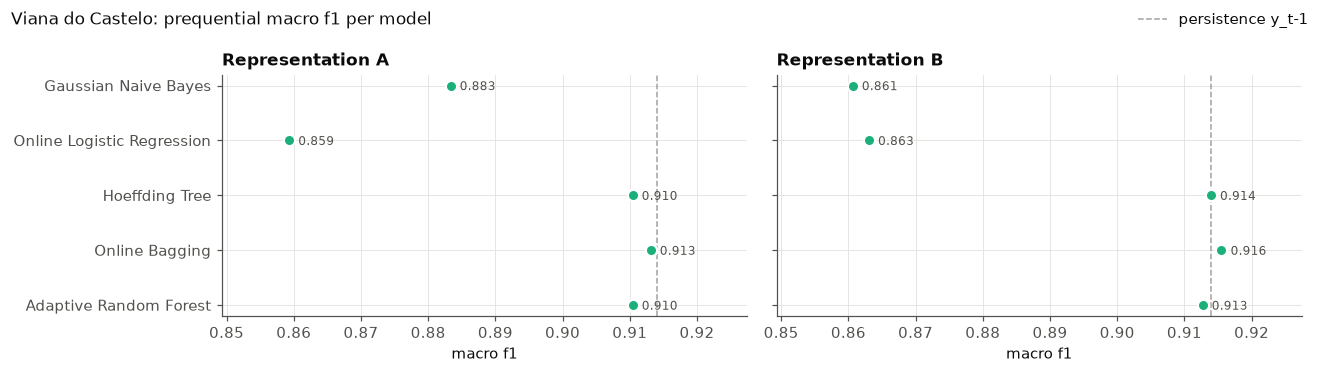

In [21]:
def dot_plot(metrics, ref, metric="macro_f1"):
    """One panel per representation; dashed line = persistence rule of this city."""
    models = list(dict.fromkeys(metrics["model"]))[::-1]
    vals = pd.concat([metrics[metric], pd.Series([ref[metric]])])
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True, sharex=True)
    for ax, rep in zip(axes, ["A", "B"]):
        sub = metrics[metrics["representation"] == rep].set_index("model").loc[models, metric]
        ax.axvline(ref[metric], color=GREY, linestyle="--", linewidth=1, label="persistence y_t-1")
        ax.scatter(sub, range(len(models)), s=55, color=AQUA, edgecolor="white", linewidth=1.5, zorder=3)
        for i, v in enumerate(sub):
            ax.annotate(f"{v:.3f}", (v, i), xytext=(6, -3), textcoords="offset points", fontsize=8, color=INK_2)
        ax.set_yticks(range(len(models)), models)
        ax.set_xlim(vals.min() - 0.01, vals.max() + 0.012)
        ax.set_xlabel(metric.replace("_", " "))
        ax.set_title(f"Representation {rep}", loc="left")
    fig.suptitle(f"{CITY['name']}: prequential {metric.replace('_', ' ')} per model", x=0.01, ha="left")
    fig.tight_layout()
    fig.legend(*axes[0].get_legend_handles_labels(), loc="upper right")
    return fig

fig = dot_plot(metrics, ref, "macro_f1")
plots.save(fig, cfg, f"{CITY_KEY}_09_models_vs_persistence")
plt.show()

### 10.4 Does temporal context help? Representation B − A

**Common comparison question (Ch. 8):** does recent temporal context improve prediction compared with only the most recent observation? Same models, same events; only the representation changes (Ch. 12.10).

In [22]:
wide = metrics.pivot_table(index="model", columns="representation", values=["macro_f1", "recall"], sort=False)
gain = pd.DataFrame({
    "macro_f1 A": wide[("macro_f1", "A")], "macro_f1 B": wide[("macro_f1", "B")],
    "Δ macro_f1 (B − A)": wide[("macro_f1", "B")] - wide[("macro_f1", "A")],
    "Δ recall humid (B − A)": wide[("recall", "B")] - wide[("recall", "A")],
})
gain.round(4)

,macro_f1 A,macro_f1 B,Δ macro_f1 (B − A),Δ recall humid (B − A)
model,,,,
Gaussian Naive Bayes,0.8833,0.8606,-0.0227,0.0247
Online Logistic Regression,0.8593,0.8631,0.0037,-0.0257
Hoeffding Tree,0.9104,0.9139,0.0035,0.0046
Online Bagging,0.9131,0.9155,0.0024,0.0149
Adaptive Random Forest,0.9104,0.9127,0.0023,-0.0047


* Context helps the **tree-based learners slightly**: Hoeffding Tree +0.0035, Adaptive Random Forest +0.0023, Online Bagging +0.0024 in Macro-F1, and Online Bagging gains +1.5 points of Recall on the humid class.
* Context **hurts Gaussian Naive Bayes (−0.023)**: the extra features are strongly correlated with RH(t−1) (rolling means of RH), which breaks the independence assumption and double-counts the same evidence.
* Logistic Regression barely changes (+0.004).
* The gains are small compared with the gap to persistence, so the main signal is RH(t−1) itself.

> 📝 **For the report:** answer the common question for Viana do Castelo: does context help, for which learners, and why?

### 10.5 Confusion matrices

**Requirement (Ch. 11.1).** All runs as counts, then the best model of each representation as a figure. Positive class = humid.

tn    fp    fn    tp  \
representation model                                                
A              Gaussian Naive Bayes        7927   467  1579  7571   
               Online Logistic Regression  6793  1601   849  8301   
               Hoeffding Tree              7693   701   869  8281   
               Online Bagging              7657   737   785  8365   
               Adaptive Random Forest      7573   821   747  8403   
B              Gaussian Naive Bayes        7304  1090  1353  7797   
               Online Logistic Regression  7083  1311  1084  8066   
               Hoeffding Tree              7713   681   827  8323   
               Online Bagging              7565   829   649  8501   
               Adaptive Random Forest      7655   739   790  8360   

                                           missed humid hours (fn) %  \
representation model                                                   
A              Gaussian Naive Bayes                          17.3000   
               Online Logistic Regression                     9.3000   
               Hoeffding Tree                                 9.5000   
               Online Bagging                                 8.6000   
               Adaptive Random Forest                         8.2000   
B              Gaussian Naive Bayes                          14.8000   
               Online Logistic Regression                    11.8000   
               Hoeffding Tree                                 9.0000   
               Online Bagging                                 7.1000   
               Adaptive Random Forest                         8.6000   

                                           false alarms (fp) %  
representation model                                            
A              Gaussian Naive Bayes                     5.6000  
               Online Logistic Regression              19.1000  
               Hoeffding Tree                           8.4000  
               Online Bagging                           8.8000  
               Adaptive Random Forest                   9.8000  
B              Gaussian Naive Bayes                    13.0000  
               Online Logistic Regression              15.6000  
               Hoeffding Tree                           8.1000  
               Online Bagging                           9.9000  
               Adaptive Random Forest                   8.8000

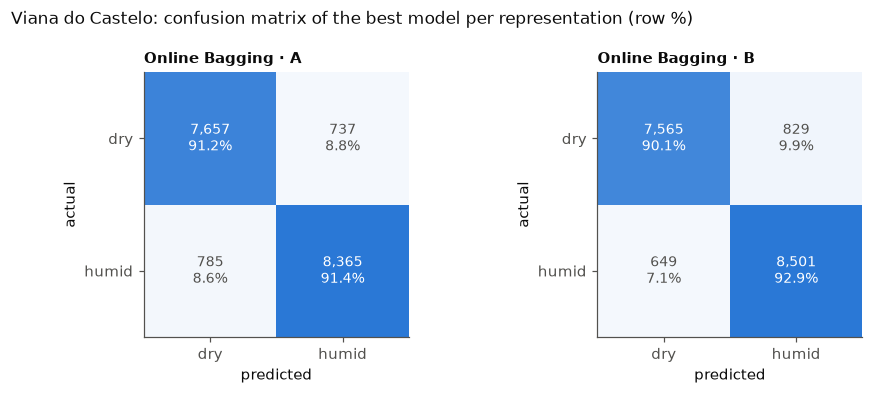

In [23]:
cm = metrics.set_index(["representation", "model"])[["tn", "fp", "fn", "tp"]]
cm["missed humid hours (fn) %"] = 100 * cm["fn"] / (cm["fn"] + cm["tp"])
cm["false alarms (fp) %"] = 100 * cm["fp"] / (cm["fp"] + cm["tn"])
display(cm.round(1))

best = metrics.loc[metrics.groupby("representation")["macro_f1"].idxmax()]
fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.6))
cmap = LinearSegmentedColormap.from_list("cm", ["#f4f8fd", BLUE])
for ax, (_, r) in zip(axes, best.iterrows()):
    m = np.array([[r["tn"], r["fp"]], [r["fn"], r["tp"]]])
    ax.imshow(m, cmap=cmap)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{int(m[i, j]):,}\n{m[i, j] / m[i].sum():.1%}", ha="center", va="center",
                    color="white" if m[i, j] > m.max() / 2 else INK_2, fontsize=9)
    ax.set_xticks([0, 1], ["dry", "humid"]); ax.set_yticks([0, 1], ["dry", "humid"])
    ax.set_xlabel("predicted"); ax.set_ylabel("actual"); ax.grid(False)
    ax.set_title(f"{r['model']} · {r['representation']}", loc="left", fontsize=10)
fig.suptitle(f"{CITY['name']}: confusion matrix of the best model per representation (row %)", x=0.01, ha="left")
fig.tight_layout()
plots.save(fig, cfg, f"{CITY_KEY}_10_confusion_best")
plt.show()

* The best model in both representations is **Online Bagging**. With B it misses **7.1 % of humid hours** (649 of 9 150) and raises **9.9 % false alarms** on dry hours (829 of 8 394): errors are spread over both classes, not concentrated on the event.
* Gaussian NB-A misses the most humid hours (17.3 %), Logistic Regression A raises the most false alarms (19.1 %).

> 📝 **For the report:** which error is worse for the store, a missed humid hour or a false alarm, and which model handles that best?

### 10.6 Performance over time

Sliding-window Macro-F1 over the last 500 events (`protocol.evaluation_window`). Drops show periods where the regime is harder to anticipate.

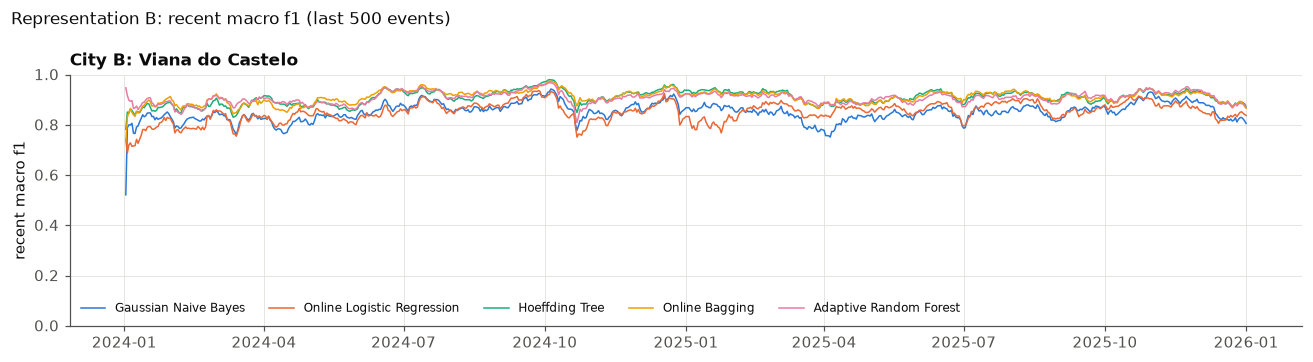

,min,max,worst window ends,best window ends
model,,,,
Adaptive Random Forest,0.8090,0.9678,2024-10-21,2024-10-03
Gaussian Naive Bayes,0.7513,0.9427,2025-04-04,2024-10-04
Hoeffding Tree,0.8301,0.9799,2024-03-11,2024-10-03
Online Bagging,0.8437,0.9738,2024-03-11,2024-10-03
Online Logistic Regression,0.7511,0.9368,2024-10-21,2024-09-26


,mean recent macro F1 (all models)
season,
DJF,0.8830
MAM,0.8663
JJA,0.8975
SON,0.9018


In [24]:
season_of = pdf.set_index("timestamp")["season"]
lookup_season = lambda ts: season_of.loc[ts].values

fig = plots.recent_performance(history, cfg, representation="B")
plots.save(fig, cfg, f"{CITY_KEY}_11_recent_macro_f1_B")
plt.show()

W = cfg["protocol"]["evaluation_window"]
h = history[(history["representation"] == "B") & (history["n"] >= W)]     # skip the first, not yet full window
summary = h.groupby("model")["recent_macro_f1"].agg(["min", "idxmin", "max", "idxmax"])
summary["worst window ends"] = h.loc[summary["idxmin"], "timestamp"].dt.strftime("%Y-%m-%d").values
summary["best window ends"] = h.loc[summary["idxmax"], "timestamp"].dt.strftime("%Y-%m-%d").values
display(summary.drop(columns=["idxmin", "idxmax"]))
by_season = h.assign(season=lookup_season(h["timestamp"])).groupby("season", observed=True)["recent_macro_f1"].mean()
by_season.to_frame("mean recent macro F1 (all models)")

* The ranking is stable over two years: the three tree-based models stay above Naive Bayes and Logistic Regression in almost every window, so the ordering in 10.2 is not driven by one period.
* All models rise and fall together, so the variation comes from how hard the weather is to anticipate, not from one model failing. The best windows end in late September / early October 2024 (Macro-F1 up to 0.97–0.98, during the long saturated spell of 1–3 October); the sharpest common drop follows in the second half of October 2024.
* By season, performance is **lowest in spring** (MAM), when humid episodes are shortest (median 5 h, Section 8.1) and the regime switches most often, and highest in summer and autumn, when long spells make the next hour easy to anticipate.

> 📝 **For the report:** when does performance drop, and what happens in the weather at those times?

### 10.7 Cost: prediction and update time per event

**Requirement (Ch. 11.2).** Milliseconds per event on this machine (Apple Silicon); absolute values depend on the hardware, ratios are what matters.

macro_f1  pred_ms_per_event  \
representation model                                                     
A              Gaussian Naive Bayes          0.8833             0.0227   
               Online Logistic Regression    0.8593             0.0004   
               Hoeffding Tree                0.9104             0.0021   
               Online Bagging                0.9131             0.0125   
               Adaptive Random Forest        0.9104             0.0171   
B              Gaussian Naive Bayes          0.8606             0.0260   
               Online Logistic Regression    0.8631             0.0005   
               Hoeffding Tree                0.9139             0.0022   
               Online Bagging                0.9155             0.0132   
               Adaptive Random Forest        0.9127             0.0166   

                                           update_ms_per_event  \
representation model                                             
A              Gaussian Naive Bayes                     0.0009   
               Online Logistic Regression               0.0009   
               Hoeffding Tree                           0.0045   
               Online Bagging                           0.0254   
               Adaptive Random Forest                   0.1068   
B              Gaussian Naive Bayes                     0.0017   
               Online Logistic Regression               0.0012   
               Hoeffding Tree                           0.0085   
               Online Bagging                           0.0451   
               Adaptive Random Forest                   0.1160   

                                           total ms / event  
representation model                                         
A              Gaussian Naive Bayes                  0.0237  
               Online Logistic Regression            0.0013  
               Hoeffding Tree                        0.0066  
               Online Bagging                        0.0379  
               Adaptive Random Forest                0.1240  
B              Gaussian Naive Bayes                  0.0277  
               Online Logistic Regression            0.0017  
               Hoeffding Tree                        0.0106  
               Online Bagging                        0.0583  
               Adaptive Random Forest                0.1326

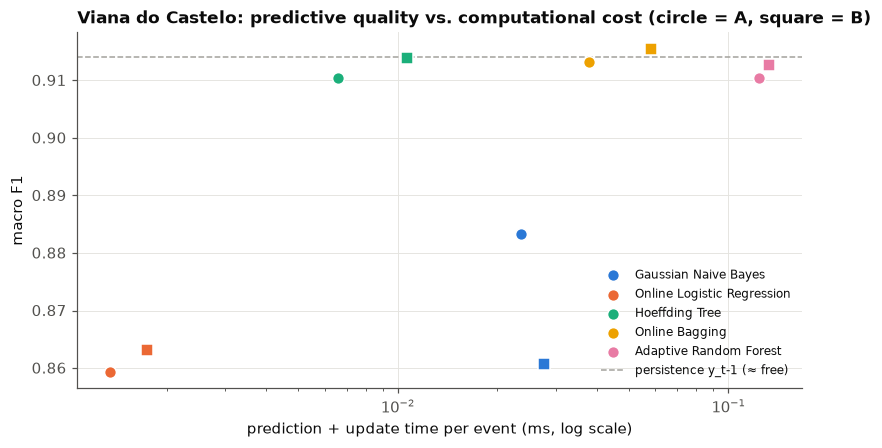

In [25]:
cost = metrics.set_index(["representation", "model"])[["macro_f1", "pred_ms_per_event", "update_ms_per_event"]]
cost["total ms / event"] = cost["pred_ms_per_event"] + cost["update_ms_per_event"]
display(cost.round(4))

markers = {"A": "o", "B": "s"}
models = list(dict.fromkeys(metrics["model"]))
fig, ax = plt.subplots(figsize=(8.5, 4.2))
for m, color in zip(models, MODEL_COLORS):
    for rep in ("A", "B"):
        r = metrics[(metrics["model"] == m) & (metrics["representation"] == rep)].iloc[0]
        ax.scatter(r["pred_ms_per_event"] + r["update_ms_per_event"], r["macro_f1"], s=60, color=color,
                   marker=markers[rep], edgecolor="white", linewidth=1, zorder=3,
                   label=m if rep == "A" else None)
ax.axhline(ref["macro_f1"], color=GREY, linestyle="--", linewidth=1, label="persistence y_t-1 (≈ free)")
ax.set_xscale("log")
ax.set_xlabel("prediction + update time per event (ms, log scale)")
ax.set_ylabel("macro F1")
ax.set_title(f"{CITY['name']}: predictive quality vs. computational cost (circle = A, square = B)", loc="left")
ax.legend(fontsize=8, loc="lower right")
plots.save(fig, cfg, f"{CITY_KEY}_12_quality_vs_cost")
plt.show()

* All models are far below 1 ms per event, while the stream produces **one event per hour**: none of them is constrained by time here.
* Relative costs differ by two orders of magnitude: **Adaptive Random Forest is the most expensive (0.13–0.15 ms/event, about 2.5–3× Online Bagging and 13–18× Hoeffding Tree)** without being more accurate than Online Bagging. Logistic Regression is the cheapest (≈ 0.002 ms).
* Representation B nearly doubles the update cost of Hoeffding Tree (0.0045 → 0.0088 ms) and Online Bagging (0.026 → 0.048 ms); for ARF it adds ≈ 20 %.
* Hoeffding Tree B reaches the persistence level at a fraction of the ensemble cost.

> 📝 **For the report:** is the small gain of the ensembles worth their cost? Which approach would you recommend for continuous monitoring (Ch. 13.2)?

## 11. Individual experiments (additional analysis, not part of the official comparison)

All experiments use a **copy** of the configuration (`my_cfg`) and fresh models; nothing is saved with `save_results`, so the official results above and notebook 03 are unchanged. One factor is changed at a time (Ch. 12.10).

### 11.1 Where do the errors happen? (diagnostic replay)

`run_prequential` reports aggregate metrics only. To see *which* hours are misclassified, the best official model (Online Bagging, Representation B) is replayed once more with a fresh instance, the same events and the same PREDICT → EVALUATE → LEARN order, storing each prediction. The assertion checks that this replay reproduces the official accuracy exactly.

⚠️ **Team note:** the temporary guidance above asks not to re-implement the evaluation loop in a city notebook. This replay is a read-only diagnostic (it writes no result file). If we keep it, agree with Khadija whether to keep it here or to add an off-by-default `keep_predictions` option to `evaluate.run_prequential`.

In [26]:
def replay_predictions(model, stream):
    """Diagnostic copy of the prequential order: learn on warm-up, then PREDICT -> (store) -> LEARN."""
    for e in stream["warm"]:
        model.learn_one(e["x"], e["y"])
    rows = []
    for e in stream["eval"]:
        y_pred = model.predict_one(e["x"])          # 1) predict with past-only state
        rows.append((e["timestamp"], e["y"], y_pred))  # 2) evaluated below, before nothing else uses y
        model.learn_one(e["x"], e["y"])             # 3) learn
    return pd.DataFrame(rows, columns=["timestamp", "y", "pred"])

BEST = "Online Bagging"
diag = replay_predictions(make_models(cfg)[BEST], streams["B"])
official = metrics[(metrics["model"] == BEST) & (metrics["representation"] == "B")]["accuracy"].iloc[0]
assert abs((diag["pred"] == diag["y"]).mean() - official) < 1e-12, "replay differs from the official run"

lookup = pdf.set_index("timestamp")
diag["rh"] = lookup.loc[diag["timestamp"], "relative_humidity_2m"].values
diag["y_prev"] = lookup["y"].shift(1).loc[diag["timestamp"]].values
diag["switch"] = diag["y"] != diag["y_prev"]                   # the regime changes at this hour
diag["model_error"] = diag["pred"] != diag["y"]
diag["persistence_error"] = diag["y_prev"] != diag["y"]        # persistence is wrong exactly at switches
diag["distance to tau_H (pp)"] = (diag["rh"] - TAU_H).abs()

by_switch = diag.groupby(diag["switch"].map({False: "regime continues", True: "regime switches"})).agg(
    hours=("y", "size"), model_errors=("model_error", "sum"), persistence_errors=("persistence_error", "sum"))
by_switch["model error rate"] = by_switch["model_errors"] / by_switch["hours"]
by_switch["share of all model errors"] = by_switch["model_errors"] / by_switch["model_errors"].sum()
display(by_switch.round(3))

bands = pd.cut(diag["distance to tau_H (pp)"], [-0.1, 1, 3, 5, 10, 100], labels=["≤ 1", "1–3", "3–5", "5–10", "> 10"])
by_band = diag.groupby(bands, observed=True).agg(
    hours=("y", "size"), model_error_rate=("model_error", "mean"), persistence_error_rate=("persistence_error", "mean"))
by_band["share of hours"] = by_band["hours"] / by_band["hours"].sum()
by_band["share of model errors"] = diag.groupby(bands, observed=True)["model_error"].sum() / diag["model_error"].sum()
by_band.round(3)

,hours,model_errors,persistence_errors,model error rate,share of all model errors
switch,,,,,
regime continues,16038,314,0,0.0200,0.2120
regime switches,1506,1164,1506,0.7730,0.7880


,hours,model_error_rate,persistence_error_rate,share of hours,share of model errors
distance to tau_H (pp),,,,,
≤ 1,1561,0.3700,0.3890,0.0890,0.3910
1–3,2085,0.2250,0.2220,0.1190,0.3170
3–5,2127,0.1140,0.1070,0.1210,0.1640
5–10,4792,0.0320,0.0360,0.2730,0.1030
> 10,6979,0.0050,0.0050,0.3980,0.0240


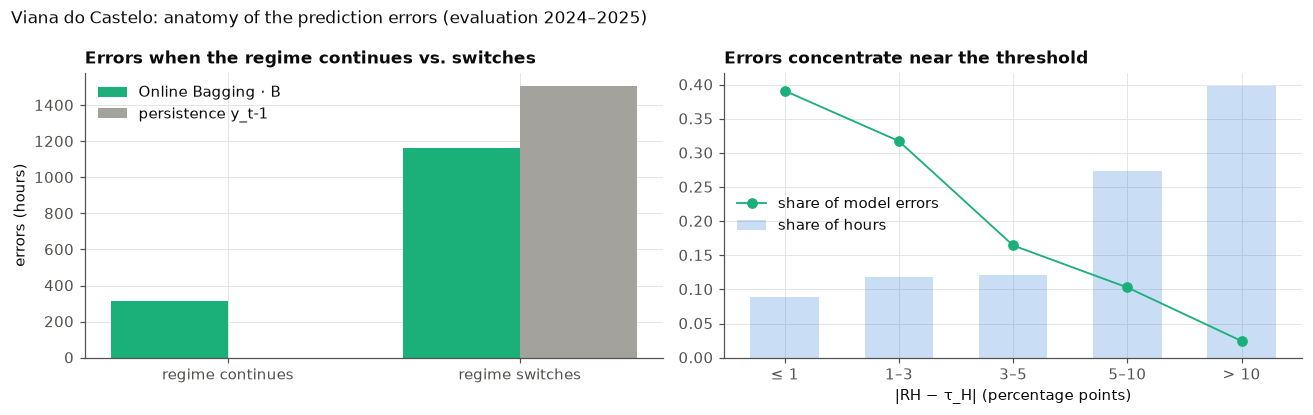

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
ax = axes[0]
x = np.arange(len(by_switch))
ax.bar(x - 0.2, by_switch["model_errors"], 0.4, color=AQUA, label=f"{BEST} · B")
ax.bar(x + 0.2, by_switch["persistence_errors"], 0.4, color=GREY, label="persistence y_t-1")
ax.set_xticks(x, by_switch.index); ax.set_ylabel("errors (hours)")
ax.set_title("Errors when the regime continues vs. switches", loc="left"); ax.legend()
ax = axes[1]
x = np.arange(len(by_band))
ax.bar(x, by_band["share of hours"], 0.6, color=HUMID, alpha=0.25, label="share of hours")
ax.plot(x, by_band["share of model errors"], "o-", color=AQUA, label="share of model errors")
ax.set_xticks(x, by_band.index); ax.set_xlabel("|RH − τ_H| (percentage points)")
ax.set_title("Errors concentrate near the threshold", loc="left"); ax.legend()
fig.suptitle(f"{CITY['name']}: anatomy of the prediction errors (evaluation 2024–2025)", x=0.01, ha="left")
fig.tight_layout()
plots.save(fig, cfg, f"{CITY_KEY}_exp_error_anatomy")
plt.show()

* The regime switches in **1 506 of 17 544 evaluation hours (8.6 %)**. Persistence is wrong in exactly those hours and right in all others.
* Online Bagging B anticipates **23 % of the switches** (342 of 1 506) but pays for it with **314 errors in hours where the regime simply continues**. **79 % of its errors are at switches.** Its small net gain over persistence is the balance of these two effects.
* **71 % of the model's errors happen when RH is within ±3 points of τ_H**, although only 21 % of the hours lie there. Far from the threshold (> 10 points, 40 % of the hours) the error rate is 0.5 %.
* So the difficulty of T4 is not noise in the data: it is the timing of crossings of an 82 % line by a slowly moving variable.

> 📝 **For the report:** what does this say about the limit of predicting T4 one hour ahead, and about what a better feature would need to capture?

### 11.2 Does more context help? Three one-factor experiments

Each experiment changes **one** thing relative to the official Representation B and re-runs all five models on fresh instances:

| Experiment | Change | Why it could help here |
|---|---|---|
| E1 temperature context | `rolling_variables += ["temperature_2m"]` (delta, 6 h / 24 h mean and std of temperature) | RH depends on temperature: night cooling raises RH |
| E2 other windows | `windows = [3, 12, 48]` instead of `[6, 24]` | shorter reaction and a longer memory of the coastal spells |
| E3 hour of day | add sin/cos of the local hour, scaled to [0, 1] | the strong daily cycle of Section 8.2; the clock time of hour *t* is known in advance, so it is not leakage |

In [28]:
hour_of = pdf.set_index("timestamp")["hour"]

def with_hour(city_streams):
    """Add the local hour of day (known in advance) as two cyclic features in [0, 1]."""
    out = {}
    for rep, parts in city_streams.items():
        out[rep] = {}
        for part, events in parts.items():
            hours = hour_of.loc[[e["timestamp"] for e in events]].to_numpy()
            out[rep][part] = [
                {**e, "x": {**e["x"], "hour_sin": (np.sin(2 * np.pi * h / 24) + 1) / 2,
                                     "hour_cos": (np.cos(2 * np.pi * h / 24) + 1) / 2}}
                for e, h in zip(events, hours)
            ]
    return out

cfg_e1 = copy.deepcopy(cfg); cfg_e1["features"]["rolling_variables"] = ["relative_humidity_2m", "temperature_2m"]
cfg_e2 = copy.deepcopy(cfg); cfg_e2["features"]["windows"] = [3, 12, 48]
experiments = {"E1 temperature context": (cfg_e1, None), "E2 windows 3/12/48 h": (cfg_e2, None),
               "E3 hour of day": (cfg, with_hour)}

rows = [metrics[metrics["representation"] == "B"].assign(experiment="official B")]
for name, (my_cfg, transform) in experiments.items():
    check_no_leakage(prepared["raw"][CITY_KEY], TAU_H, my_cfg)          # the new features stay past-only
    s = make_streams(prepared, my_cfg)[CITY_KEY]
    s = {"B": (transform(s) if transform else s)["B"]}
    m, _ = evaluate_models(s, make_models, my_cfg, CITY_KEY)           # fresh models; NOT saved
    rows.append(m.assign(experiment=name))
exp = pd.concat(rows)

exp_table = exp.pivot_table(index="model", columns="experiment", values="macro_f1", sort=False)
exp_table = exp_table[["official B", *experiments]]
for name in experiments:
    exp_table[f"Δ {name.split()[0]}"] = exp_table[name] - exp_table["official B"]
exp_table.loc["persistence y_t-1"] = [ref["macro_f1"]] * (1 + len(experiments)) + [np.nan] * len(experiments)
exp_table.round(4)

experiment,official B,E1 temperature context,E2 windows 3/12/48 h,E3 hour of day,Δ E1,Δ E2,Δ E3
model,,,,,,,
Gaussian Naive Bayes,0.8606,0.8548,0.8674,0.8671,-0.0058,0.0068,0.0064
Online Logistic Regression,0.8631,0.8811,0.8772,0.8731,0.0181,0.0142,0.0101
Hoeffding Tree,0.9139,0.9130,0.9141,0.9134,-0.0009,0.0001,-0.0005
Online Bagging,0.9155,0.9198,0.9195,0.9201,0.0043,0.0039,0.0046
Adaptive Random Forest,0.9127,0.9123,0.9105,0.9137,-0.0004,-0.0022,0.0010
persistence y_t-1,0.9140,0.9140,0.9140,0.9140,NaN,NaN,NaN


In [29]:
exp.pivot_table(index="model", columns="experiment", values="update_ms_per_event", sort=False)[
    ["official B", *experiments]].round(4)

experiment,official B,E1 temperature context,E2 windows 3/12/48 h,E3 hour of day
model,,,,
Gaussian Naive Bayes,0.0017,0.0023,0.0022,0.0022
Online Logistic Regression,0.0012,0.0015,0.0015,0.0013
Hoeffding Tree,0.0085,0.0121,0.0102,0.0104
Online Bagging,0.0451,0.0635,0.0525,0.0567
Adaptive Random Forest,0.1160,0.1480,0.1054,0.1135


* Extra context helps **Online Bagging and Logistic Regression**, not the other learners. Online Bagging rises from 0.9155 to **0.919–0.920 with each of the three changes** (best: hour of day, 0.9201), i.e. about +0.006 over persistence instead of +0.0015.
* Logistic Regression gains the most (+0.010 to +0.018, best with temperature context) but stays well below persistence.
* Hoeffding Tree and Adaptive Random Forest are essentially unchanged (−0.002 to +0.001); Gaussian Naive Bayes moves by less than ±0.007 and stays the weakest.
* Costs grow with the number of features (Online Bagging 0.06–0.07 ms/event, ARF up to 0.17 ms/event), still negligible for an hourly stream.
* None of these changes alters the conclusion that RH(t−1) carries most of the signal. **These are individual results:** if we want one of them in the official run, it has to be agreed with Khadija, changed in `config.yaml` / `src/`, and both cities re-run.

> 📝 **For the report:** which experiment would you propose as a shared protocol change, if any, and why?

## 12. Summary for the report (City B: Viana do Castelo)

**Stream (descriptive):**

1. Clean stream: no missing or invalid values; extremes (storms, heavy rain, saturation, a heat day) are real weather and are kept.
2. Humid regime (RH ≥ 82 %) in about half of the hours (52 % in 2024–2025), **most frequent in summer and autumn**, least in spring.
3. Humid air comes in **long spells**: 128 humid episodes ≥ 24 h, 15 ≥ 72 h, longest 252 h; 45 % of humid hours lie in spells of a day or more.
4. Strong **daily cycle**: humid nights and mornings, drier afternoons in spring and summer; the dry afternoon window shrinks in autumn.

**Models (predictive):**

5. The persistence rule (Macro-F1 0.914) is a very strong reference; only tree-based learners reach it, and Online Bagging B is the best official model (0.9155).
6. Representation B helps the tree models slightly and hurts Gaussian Naive Bayes.
7. Errors are concentrated at regime switches and within ±3 points of τ_H.
8. All models are fast enough for an hourly stream; Adaptive Random Forest costs the most without being the best.

> 📝 **For the report:** write the City B section (report Section 4) and your part of Sections 6–7 in your own words, using the evidence above.